# Dataset 3 | Zhang 2018 vs Zhang 2020 — Direct Comparison

**Purpose:** Compare the two Smart-seq2 datasets using shared patients, exact matching cell IDs, and tumor CD4/CD8 composition. Analyses already completed separately (t-SNE, within-dataset MSI/MSS tests, and gene exploration) are **not repeated** here.

**References:** [Zhang et al. (2018), *Nature*](https://doi.org/10.1038/s41586-018-0694-x) · [Zhang et al. (2020), *Cell*](https://doi.org/10.1016/j.cell.2020.03.048)

**Important:** The 2020 study reused a subset of the 2018 T cells. These are **not independent datasets**, so agreement between them cannot be claimed as independent replication. All comparisons below are descriptive; no new p-values are calculated.

## 1. Load validated metadata
Load the metadata saved by the two exploration notebooks, and use the published MSI labels for all patients in each dataset.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_DIR = Path("/cfs/earth/scratch/suereser/crc_singlecell")
RESULTS_DIR = PROJECT_DIR / "results"
COMPARISON_DIR = RESULTS_DIR / "dataset_comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

p18 = RESULTS_DIR / "GSE108989" / "cell_metadata.csv"
p20 = RESULTS_DIR / "GSE146771" / "cell_metadata.csv"
for path in [p18, p20]:
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Run the metadata-export section in the corresponding dataset notebook.")

d18 = pd.read_csv(p18, low_memory=False)
d20 = pd.read_csv(p20, low_memory=False)

required18 = {"UniqueCell_ID", "Patient_ID", "majorCluster", "sampleType"}
required20 = {"Barcode", "Sample", "Tissue", "Global_Cluster"}
for name, df, needed in [("2018", d18, required18), ("2020", d20, required20)]:
    absent = needed - set(df.columns)
    if absent:
        raise ValueError(f"{name} metadata lacks columns: {sorted(absent)}")

MSI_2018 = {"P0123", "P0413", "P0825", "P0909"}
MSS_2018 = {"P0215", "P0309", "P0411", "P0701", "P1012", "P1207", "P1212", "P1228"}
SMARTSEQ_2020 = {"P0104", "P0305", "P0309", "P0411", "P0413", "P0720", "P0728", "P0825", "P1212", "P1228"}
MSI_2020 = {"P0413", "P0825"}

for df, patient_col in [(d18, "Patient_ID"), (d20, "Sample")]:
    df[patient_col] = df[patient_col].astype(str).str.strip()

if set(d18["Patient_ID"]) != MSI_2018 | MSS_2018:
    raise ValueError("2018 patient IDs do not match the published 12-patient cohort.")
if set(d20["Sample"]) != SMARTSEQ_2020:
    raise ValueError("2020 metadata is not the expected 10-patient Smart-seq2 cohort.")

d18["MSI_Status"] = d18["Patient_ID"].map({
    **{p: "MSI-H" for p in MSI_2018}, **{p: "MSS" for p in MSS_2018}})
d20["MSI_Status"] = d20["Sample"].map({
    p: "MSI-H" if p in MSI_2020 else "MSS" for p in SMARTSEQ_2020})

def normalise_tissue(values):
    tissue_map = {
        "n": "Normal", "normal": "Normal", "normal tissue": "Normal", "adjacent normal": "Normal",
        "p": "Peripheral Blood", "blood": "Peripheral Blood", "peripheral blood": "Peripheral Blood", "pbmc": "Peripheral Blood",
        "t": "Tumor", "tumor": "Tumor", "tumour": "Tumor", "tumor tissue": "Tumor", "tumour tissue": "Tumor",
    }
    cleaned = values.astype(str).str.strip().str.lower()
    output = cleaned.map(tissue_map)
    if output.isna().any():
        raise ValueError(f"Unrecognised tissue values: {sorted(cleaned[output.isna()].unique())}")
    return output

d18["Tissue"] = normalise_tissue(d18["sampleType"].astype(str).str[0])
d20["Tissue"] = normalise_tissue(d20["Tissue"])
d18["T_Cell_Type"] = d18["majorCluster"].astype(str).str.extract(r"^(CD4|CD8)_", expand=False).map({"CD4":"CD4+", "CD8":"CD8+"})
d20["Global_Cluster"] = d20["Global_Cluster"].astype(str).str.strip()
d18["UniqueCell_ID"] = d18["UniqueCell_ID"].astype(str).str.strip()
d20["Barcode"] = d20["Barcode"].astype(str).str.strip()

print(f"Loaded 2018: {len(d18):,} cells, {d18['Patient_ID'].nunique()} patients")
print(f"Loaded 2020: {len(d20):,} cells, {d20['Sample'].nunique()} patients")

Loaded 2018: 11,138 cells, 12 patients
Loaded 2020: 10,468 cells, 10 patients


## 2. Dataset overview and shared patients
Check cohort scope before making any direct comparison. The 2020 Smart-seq2 dataset is a **subset of the full 18-patient 2020 study**.

In [2]:
overview = pd.DataFrame([
    {"Dataset": "Zhang 2018", "Scope": "T-cell focused", "Cells": len(d18),
     "Patients": d18["Patient_ID"].nunique(), "MSI-H": len(MSI_2018), "MSS": len(MSS_2018),
     "CD4/CD8 cells": int(d18["T_Cell_Type"].notna().sum())},
    {"Dataset": "Zhang 2020 (Smart-seq2)", "Scope": "Immune + non-immune cells", "Cells": len(d20),
     "Patients": d20["Sample"].nunique(), "MSI-H": len(MSI_2020), "MSS": len(SMARTSEQ_2020 - MSI_2020),
     "CD4/CD8 cells": int(d20["Global_Cluster"].isin(["CD4 T cell", "CD8 T cell"]).sum())}
])
display(overview)

shared_patients = sorted(set(d18["Patient_ID"]) & set(d20["Sample"]))
patient_compare = pd.DataFrame({
    "Patient": shared_patients,
    "2018 MSI": ["MSI-H" if p in MSI_2018 else "MSS" for p in shared_patients],
    "2020 MSI": ["MSI-H" if p in MSI_2020 else "MSS" for p in shared_patients],
})
assert (patient_compare["2018 MSI"] == patient_compare["2020 MSI"]).all(), "Conflicting MSI labels."
print(f"Shared patients: {len(shared_patients)}")
display(patient_compare)
overview.to_csv(COMPARISON_DIR / "dataset_overview.csv", index=False)
patient_compare.to_csv(COMPARISON_DIR / "shared_patients.csv", index=False)

,Dataset,Scope,Cells,Patients,MSI-H,MSS,CD4/CD8 cells
0,Zhang 2018,T-cell focused,11138,12,4,8,8530
1,Zhang 2020 (Smart-seq2),Immune + non-immune cells,10468,10,2,8,5548


Shared patients: 6


,Patient,2018 MSI,2020 MSI
0,P0309,MSS,MSS
1,P0411,MSS,MSS
2,P0413,MSI-H,MSI-H
3,P0825,MSI-H,MSI-H
4,P1212,MSS,MSS
5,P1228,MSS,MSS


## 3. Exact shared cells and annotation agreement
Match **2018 `UniqueCell_ID`** to **2020 `Barcode`**, not `CellName`. Compare the **same physical cells** across the two annotation systems.

Exact shared annotated T cells: 4,494
Share of 2018 annotated CD4/CD8 cells: 52.7%
Patient-label mismatches: 0; tissue-label mismatches: 0
2020 annotations of cells already observed in 2018:


Global_Cluster,CD4 T cell,CD8 T cell,ILC
T_Cell_Type,,,
CD4+,2405,0,2
CD8+,0,2087,0


,Shared cells
Patient_ID,
P0309,479
P0411,597
P0413,599
P0825,936
P1212,941
P1228,942


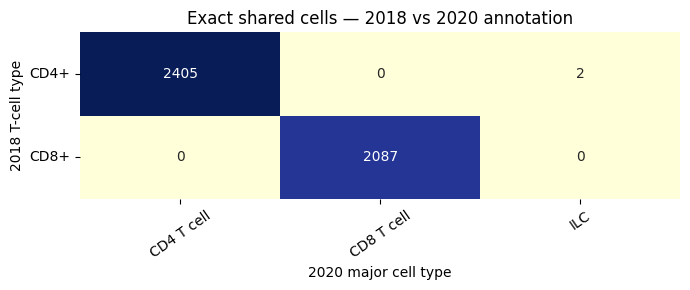

In [3]:
d18_tcells = d18[d18["T_Cell_Type"].isin(["CD4+", "CD8+"])].copy()
if d18_tcells["UniqueCell_ID"].duplicated().any() or d20["Barcode"].duplicated().any():
    raise ValueError("Cell identifiers must be unique within each dataset; inspect duplicates before merging.")

matched = d18_tcells[
    ["UniqueCell_ID", "Patient_ID", "Tissue", "T_Cell_Type"]
].merge(
    d20[["Barcode", "Sample", "Tissue", "Global_Cluster"]],
    left_on="UniqueCell_ID", right_on="Barcode", how="inner", validate="one_to_one",
    suffixes=("_2018", "_2020")
)
if matched.empty:
    raise ValueError("No matching cell IDs. Check that the 2020 'Barcode' column was used (not 'CellName').")

n_patient_mismatches = int((matched["Patient_ID"] != matched["Sample"]).sum())
n_tissue_mismatches = int((matched["Tissue_2018"] != matched["Tissue_2020"]).sum())
print(f"Exact shared annotated T cells: {len(matched):,}")
print(f"Share of 2018 annotated CD4/CD8 cells: {100*len(matched)/len(d18_tcells):.1f}%")
print(f"Patient-label mismatches: {n_patient_mismatches}; tissue-label mismatches: {n_tissue_mismatches}")
assert n_patient_mismatches == 0, "Overlapping cell IDs have conflicting patient IDs."

annotation_table = pd.crosstab(matched["T_Cell_Type"], matched["Global_Cluster"])
print("2020 annotations of cells already observed in 2018:")
display(annotation_table)
matched_by_patient = matched.groupby("Patient_ID").size().rename("Shared cells").reindex(shared_patients, fill_value=0)
display(matched_by_patient.to_frame())

annotation_table.to_csv(COMPARISON_DIR / "shared_cells_annotation_table.csv")
matched_by_patient.to_csv(COMPARISON_DIR / "shared_cells_by_patient.csv")

fig, ax = plt.subplots(figsize=(max(7, 1.2*annotation_table.shape[1]+2), 3))
sns.heatmap(annotation_table, annot=True, fmt="d", cmap="YlGnBu", cbar=False, linewidths=0, ax=ax)
ax.set(title="Exact shared cells — 2018 vs 2020 annotation", xlabel="2020 major cell type", ylabel="2018 T-cell type")
ax.tick_params(axis="x", labelrotation=35)
ax.tick_params(axis="y", labelrotation=0)
fig.tight_layout()
fig.savefig(COMPARISON_DIR / "shared_cell_annotation_heatmap.png", dpi=250, bbox_inches="tight")
plt.show()

In [5]:
ilc_cells = matched.loc[
    matched["Global_Cluster"] == "ILC",
    ["UniqueCell_ID", "Patient_ID", "T_Cell_Type", "Global_Cluster"]
]

display(ilc_cells)

,UniqueCell_ID,Patient_ID,T_Cell_Type,Global_Cluster
631,NTH119-20161212,P1212,CD4+,ILC
1230,TP766-20180309,P0309,CD4+,ILC


## 4. Tumor CD4 composition in shared patients
For a fairer *descriptive* comparison, use **tumor only**, the same **six patients**, and the same denominator: **CD4 / (CD4 + CD8)** within each dataset. A CD8 plot is unnecessary because its percentage is exactly 100 − CD4%.

Tumor CD4 percentage among annotated CD4/CD8 cells (not whole-tumor composition):


,Patient,MSI,2018 CD4 (%),2020 CD4 (%),2018 tumor CD4+CD8 cells,2020 tumor CD4+CD8 cells
0,P0309,MSS,64.9,62.8,285,336
1,P0411,MSS,66.3,66.2,243,269
2,P0413,MSI-H,61.1,62.2,293,323
3,P0825,MSI-H,64.8,65.3,474,531
4,P1212,MSS,42.8,47.5,355,503
5,P1228,MSS,30.5,44.2,311,471


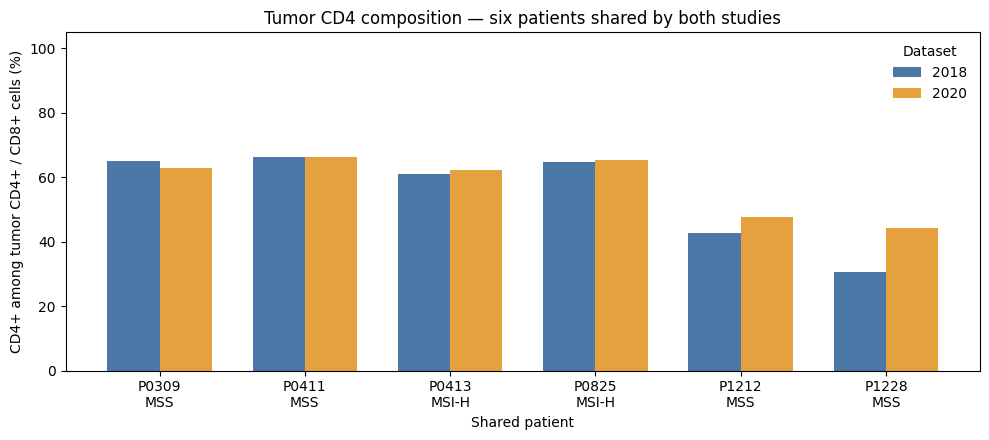

In [4]:
def tumor_cd4_share(df, patient_col, type_col, cd4_label, cd8_label):
    tumor = df.loc[
        df["Tissue"].eq("Tumor")
        & df[patient_col].isin(shared_patients)
        & df[type_col].isin([cd4_label, cd8_label])
    ]
    counts = pd.crosstab(tumor[patient_col], tumor[type_col]).reindex(
        index=shared_patients, columns=[cd4_label, cd8_label], fill_value=0)
    total = counts.sum(axis=1)
    return (100 * counts[cd4_label] / total.replace(0, np.nan)).rename("CD4 %"), total

cd4_2018, tumor_t_2018 = tumor_cd4_share(d18, "Patient_ID", "T_Cell_Type", "CD4+", "CD8+")
cd4_2020, tumor_t_2020 = tumor_cd4_share(d20, "Sample", "Global_Cluster", "CD4 T cell", "CD8 T cell")

cd4_compare = pd.DataFrame({
    "Patient": shared_patients,
    "MSI": ["MSI-H" if p in MSI_2018 else "MSS" for p in shared_patients],
    "2018 CD4 (%)": cd4_2018.reindex(shared_patients).values,
    "2020 CD4 (%)": cd4_2020.reindex(shared_patients).values,
    "2018 tumor CD4+CD8 cells": tumor_t_2018.reindex(shared_patients).values,
    "2020 tumor CD4+CD8 cells": tumor_t_2020.reindex(shared_patients).values,
})
print("Tumor CD4 percentage among annotated CD4/CD8 cells (not whole-tumor composition):")
display(cd4_compare.round(1))
cd4_compare.to_csv(COMPARISON_DIR / "shared_patients_tumor_cd4_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(cd4_compare))
width = 0.36
ax.bar(x-width/2, cd4_compare["2018 CD4 (%)"], width, label="2018", color="#4C78A8")
ax.bar(x+width/2, cd4_compare["2020 CD4 (%)"], width, label="2020", color="#E5A13D")
ax.set_xticks(x, [f"{p}\n{msi}" for p, msi in zip(cd4_compare["Patient"], cd4_compare["MSI"])])
ax.set_ylim(0, 105)
ax.set(ylabel="CD4+ among tumor CD4+ / CD8+ cells (%)", xlabel="Shared patient",
       title="Tumor CD4 composition — six patients shared by both studies")
ax.grid(False)
ax.legend(title="Dataset", frameon=False)
fig.tight_layout()
fig.savefig(COMPARISON_DIR / "shared_patients_tumor_cd4_comparison.png", dpi=250, bbox_inches="tight")
plt.show()

## 5. Interpretation and limitations

- **Overlap:** Some cell profiles and six patients occur in both datasets. They must not be treated as independent cohorts or as two independent confirmations of an MSI-associated effect.
- **Comparable quantity:** The last figure compares *CD4 among sampled tumor CD4/CD8 cells* using the same denominator. It does **not** compare the entire tumor immune-cell composition.
- **Sampling:** Both studies use FACS-enriched cells; differences may reflect selection, sampling and reannotation rather than a biological change.
- **Different scopes:** 2018 focuses on T-cell subclusters; 2020 Smart-seq2 also contains B cells, myeloid cells and non-immune cells. Their full cell-type compositions or independently generated t-SNE axes should **not** be directly compared.
- **Inference:** The within-dataset MSI-H/MSS p-values and FDR results are kept in notebooks 1 and 2. This notebook adds **no new hypothesis tests**.

**Conclusion:** Use the 2020 dataset for broader cell-type context and the 2018 dataset for detailed T-cell states, while explicitly acknowledging shared patients and reused cells.